# Laya-1.2-speedup + CarRacing — 64-token marker-aware typed-decision controller

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vtavakkoli/simple-jev/blob/main/notebooks/Laya_CarRacing_1p2_Speedup_Colab.ipynb)

**Source:** Adapted from [Laya_CarRacing_Local_Colab.ipynb](https://github.com/vtavakkoli/simple-jev/blob/main/notebooks/Laya_CarRacing_Local_Colab.ipynb). The simulator, deterministic road perception, confidence/semantic gating, launch, recovery, diagnostics and video remain in place.

**Model:** [vtava/Laya-1.2-speedup](https://huggingface.co/vtava/Laya-1.2-speedup), a V4.6 *typed-decision* model, **not** the original `convaiinnovations/laya` Router model. It downloads its unchanged base checkpoint `convaiinnovations/laya-typed-decisions` and the saved 64-token decision head. It returns option scores only. A transparent adapter builds the state/question sequences using `tinycenn_lm.standalone_decision.build_sequence`, then converts scores to the original steering/longitudinal response shape. No external inference API is called.

**Experimental warning:** The V4.6 ~1.20x benchmark refers to typed-decision inference compared with its own native teacher, **not** the old CarRacing Router baseline. This experiment does NOT imply 1.20x faster racing or better rewards. CarRacing is an out-of-domain task. Preflight checks both raw model intent and corrected intent; any semantic override gives the model **zero** effective control weight. `raw_laya` mode is an explicit uncontrolled ablation; `confidence_hybrid` is the default.

The notebook logs model calls, raw choices, option probabilities, semantic overrides, actual control blend, racing reward, visited tiles, decision latency, and exports MP4/GIF/CSV/JSON. **Running the notebook in Colab is required** to obtain actual racing results.


In [1]:
#@title 1. Install CarRacing, V4.6 runtime and pinned model dependencies
!apt-get -qq update
!apt-get -qq install -y swig > /dev/null
%pip -q install "gymnasium[box2d]==1.3.0" imageio imageio-ffmpeg pillow matplotlib pandas
%pip -q install "transformers==4.57.6" "huggingface_hub>=0.25,<1" "safetensors>=0.4"
%pip -q install "git+https://github.com/vtavakkoli/TinyCeNN-LM.git@8ba9b41894c5f0708729ad8720c2b5b3d4eafa20"


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.7/3.7 MB 56.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 98.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 113.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 93.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 49.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 120.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.

In [2]:
#@title 2. Imports, configuration, and local Laya preload
import os
os.environ["USE_TF"] = "0"

import time, json
from collections import Counter, deque
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import gymnasium as gym
import imageio.v2 as imageio
import matplotlib.pyplot as plt

from PIL import Image as PILImage
from IPython.display import Video, Image, display
from huggingface_hub import HfApi, hf_hub_download, notebook_login
from tinycenn_lm.standalone_decision import normalize_question, build_sequence, collate_items, QTYPES
import importlib.util, contextlib

MODEL_ID = "vtava/Laya-1.2-speedup"
MODEL_KEY = "laya-1.2-speedup"
ENV_ID = "CarRacing-v3"
SEED = 0

SIM_FPS = 50.0
MAX_STEPS = 3000

# The camera still gets one second, but the car is no longer held motionless for all of it.
CAMERA_WARMUP_FRAMES = 50
CAMERA_SETTLE_FRAMES = 8
MODEL_WARMUP_CALLS = 6

CONTROL_HORIZON = 4
COMPILE_HEAD = False  #@param {type:"boolean"}; optional, compilation can be slow on T4
HISTORY_LEN = 3
CONTROL_MODE = "confidence_hybrid"   # "confidence_hybrid" or "raw_laya"

# Runtime protection. These do NOT fake Laya confidence; all intervention is logged.
CONFIDENCE_FOR_FULL_TRUST = 0.35
MIN_CONSISTENT_LAYA_BLEND = 0.25
MAX_LAYA_BLEND = 0.85
ANTI_STALL_SPEED = 4.0
RECOVERY_AFTER_FRAMES = 120
STOP_AFTER_FRAMES = 500

MAX_STEER_DELTA_PER_FRAME = 0.16
MAX_LONGITUDINAL_DELTA_PER_FRAME = 0.16

VIDEO_EVERY = 2
GIF_EVERY = 6
SCAN_ROWS = [68, 62, 56, 50, 44, 38]  # near -> far

OUTPUT_DIR = Path("/content") if Path("/content").exists() else Path.cwd()
VIDEO_PATH = str(OUTPUT_DIR / "laya_1p2_speedup_car_racing.mp4")
GIF_PATH = str(OUTPUT_DIR / "laya_car_racing_local_v3.gif")
LOG_PATH = str(OUTPUT_DIR / "laya_car_racing_local_v3.json")
CSV_PATH = str(OUTPUT_DIR / "laya_car_racing_local_v3_decisions.csv")
PREFLIGHT_PATH = str(OUTPUT_DIR / "laya_car_racing_local_v3_preflight.json")

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cuda":
    torch.backends.cuda.matmul.allow_tf32 = True

print("device:", DEVICE)
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# Authenticate if the Hugging Face model is private. Credentials stay in the
# Hugging Face client and are NEVER written into experiment logs.
try:
    repo_info=HfApi().model_info(MODEL_ID)
except Exception as exc:
    print("Model may be private or Hub access needs authorization:",str(exc)[:260])
    notebook_login()
    repo_info=HfApi().model_info(MODEL_ID)

required_files={"config.json","head.safetensors","modeling_laya_speedup.py"}
remote_files={file.rfilename for file in repo_info.siblings}
assert required_files.issubset(remote_files), (
    "Hugging Face model is missing V4.6 loader/weights/configuration: ",
    sorted(required_files-remote_files))
model_cfg=json.loads(Path(hf_hub_download(repo_id=MODEL_ID,filename="config.json")).read_text())
assert model_cfg.get("source_model")=="convaiinnovations/laya-typed-decisions", model_cfg
assert int(model_cfg.get("head_context_budget",-1))==64, model_cfg
assert model_cfg.get("all_gates_passed") is True, "Published model lacks recorded validation gates"
loader_file=hf_hub_download(repo_id=MODEL_ID,filename="modeling_laya_speedup.py")
spec=importlib.util.spec_from_file_location("laya_speedup_hf_runtime",loader_file)
assert spec is not None and spec.loader is not None
runtime=importlib.util.module_from_spec(spec)
# This executes code downloaded from the selected Hugging Face repo; use a repo
# you trust. This notebook pins the repo revision in logs for reproducibility.
spec.loader.exec_module(runtime)
speedup_model,tokenizer=runtime.load_laya_speedup(
    repo_id=MODEL_ID,device=DEVICE,compile_head=COMPILE_HEAD)
speedup_model.eval().requires_grad_(False)
if tokenizer.pad_token_id is None:
    raise RuntimeError("Published tokenizer lacks a pad_token_id")
MAX_MODEL_LEN=512
HEAD_MAX_LEN=192

class TypedDecisionRouter:
    """Adapter from the original Router.predict API to V4.6 option-score logits.

    Two choice questions are scored in one B=2 batch for lower overhead. A
    probability is a model option softmax, NOT a calibrated driving confidence.
    """
    def __init__(self,model,tokenizer,device):
        self.model=model
        self.tokenizer=tokenizer
        self.device=device
        self.calls=0

    @torch.inference_mode()
    def predict(self,state,questions,model=None):
        if model not in (None,MODEL_KEY):
            raise ValueError(f"Unknown model key: {model}")
        prepared=[]
        labels=[]
        names=[]
        for name,raw_question in questions.items():
            q=normalize_question(raw_question)
            if q["t"]!="choice":
                raise ValueError("CarRacing requires choice questions")
            options=list(q["crit"].keys())
            ids,markers=build_sequence(self.tokenizer,state,q,
                max_len=MAX_MODEL_LEN,head_max_len=HEAD_MAX_LEN)
            if len(markers)!=len(options):
                raise RuntimeError(
                    f"Truncated choice markers for {name}: "
                    f"{len(markers)}/{len(options)}")
            prepared.append({"ids":ids,"markers":markers,"qtype":QTYPES[q["t"]]})
            labels.append(options)
            names.append(name)
        tensors=collate_items(prepared,int(self.tokenizer.pad_token_id))
        tensors={key:value.to(self.device) for key,value in tensors.items()}
        with (torch.autocast("cuda",dtype=torch.float16)
              if self.device=="cuda" else contextlib.nullcontext()):
            logits,_=self.model(**tensors)
        logits=logits.float().masked_fill(~tensors["marker_mask"],-1e9)
        probabilities=logits.softmax(-1).cpu().numpy()
        answers={}
        for i,name in enumerate(names):
            p=probabilities[i,:len(labels[i])]
            j=int(np.argmax(p))
            answers[name]=dict(choice=labels[i][j],
                confidence=float(p[j]),
                probabilities={label:float(value) for label,value
                               in zip(labels[i],p)},
                # Model confidence here is NOT calibrated on racing outcomes.
                confidence_kind="uncalibrated_option_softmax")
        self.calls+=1
        return {"answers":answers,"model":MODEL_ID}

router=TypedDecisionRouter(speedup_model,tokenizer,DEVICE)
print("✓ Loaded exact Hugging Face option-scoring model:",MODEL_ID)
print("✓ V4.6 context budget:",model_cfg["head_context_budget"])
print("✓ Hugging Face revision:",repo_info.sha)
print("✓ Frozen original encoder; auxiliary action head is not used")
print("✓ Outputs are uncalibrated typed-choice probabilities")
print("✓ No inference API: model executes on the Colab runtime")
print("camera/launch warm-up:",CAMERA_WARMUP_FRAMES,"frames =",CAMERA_WARMUP_FRAMES/SIM_FPS,"simulated seconds")
print("model warm-up:",MODEL_WARMUP_CALLS,"predictions")
print("control mode:",CONTROL_MODE)


device: cuda
GPU: Tesla T4


config.json: 0.00B [00:00, ?B/s]

modeling_laya_speedup.py: 0.00B [00:00, ?B/s]

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

rl_agent_config.json:   0%|          | 0.00/847 [00:00<?, ?B/s]

...

tokenizer.json: 0.00B [00:00, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/843M [00:00<?, ?B/s]

head.safetensors:   0%|          | 0.00/101M [00:00<?, ?B/s]

✓ Loaded exact Hugging Face option-scoring model: vtava/Laya-1.2-speedup
✓ V4.6 context budget: 64
✓ Hugging Face revision: ac6305fb66912b25a30b1e4ab39b7034825ae71a
✓ Frozen original encoder; auxiliary action head is not used
✓ Outputs are uncalibrated typed-choice probabilities
✓ No inference API: model executes on the Colab runtime
camera/launch warm-up: 50 frames = 1.0 simulated seconds
model warm-up: 6 predictions
control mode: confidence_hybrid


In [3]:
#@title 3. Road perception and vehicle telemetry
def road_mask_from_rgb(frame):
    img = np.asarray(frame, dtype=np.float32)
    # CarRacing asphalt is mostly grey: low RGB spread, mid brightness.
    spread = np.ptp(img, axis=2)
    mean = img.mean(axis=2)
    mask = (spread < 26) & (mean > 48) & (mean < 190)
    # Remove dashboard / car region.
    mask[82:] = False
    return mask

def _contiguous_groups(xs, max_gap=8):
    if len(xs) == 0:
        return []
    return np.split(xs, np.where(np.diff(xs) > max_gap)[0] + 1)

def scan_road(mask):
    previous_center = 48.0
    centers, widths, valid = [], [], []

    for y in SCAN_ROWS:
        # Use a 3-row band so single-pixel texture holes do not dominate.
        band = mask[max(0, y-1):min(96, y+2)].mean(axis=0)
        xs = np.flatnonzero(band >= 0.34)
        groups = [g for g in _contiguous_groups(xs) if len(g) >= 4]

        if not groups:
            centers.append(None)
            widths.append(0.0)
            valid.append(False)
            continue

        # Continuity prior: prefer the road segment nearest the previous scanline center.
        g = min(
            groups,
            key=lambda z: (
                abs((float(z[0]) + float(z[-1])) / 2.0 - previous_center),
                -len(z),
            ),
        )
        previous_center = (float(g[0]) + float(g[-1])) / 2.0
        centers.append((previous_center - 48.0) / 48.0)
        widths.append((float(g[-1]) - float(g[0]) + 1.0) / 96.0)
        valid.append(True)

    return centers, widths, valid

def read_speed(env):
    try:
        return float(np.linalg.norm(env.unwrapped.car.hull.linearVelocity))
    except Exception:
        return 0.0

def read_angular_velocity(env):
    try:
        return float(env.unwrapped.car.hull.angularVelocity)
    except Exception:
        return 0.0

def _direction_label(angle):
    if angle is None:
        return "unknown"
    if angle < -11:
        return "strong_left"
    if angle < -2.5:
        return "left"
    if angle > 11:
        return "strong_right"
    if angle > 2.5:
        return "right"
    return "straight"

def extract_visual_state(frame, speed, angular_velocity=0.0):
    centers, widths, valid = scan_road(road_mask_from_rgb(frame))
    rows = [(y, c) for y, c, ok in zip(SCAN_ROWS, centers, valid) if ok]

    # Bearing: road-center displacement at the middle look-ahead row.
    target = min(rows, key=lambda row: abs(row[0] - 50)) if rows else None
    bearing = (
        float(np.degrees(np.arctan2(48.0 * target[1], 72.0 - target[0])))
        if target else None
    )

    # Heading: how the road center moves from near to far.
    heading = (
        float(np.degrees(np.arctan2(
            48.0 * (rows[-1][1] - rows[0][1]),
            rows[0][0] - rows[-1][0]
        )))
        if len(rows) >= 2 else None
    )

    combined = None
    if bearing is not None:
        combined = float(bearing + 0.40 * (heading if heading is not None else 0.0))

    speed_band = (
        "stopped" if speed < 3 else
        "slow" if speed < 10 else
        "turn_speed" if speed < 17 else
        "cruise" if speed < 25 else
        "fast" if speed < 34 else
        "very_fast"
    )

    visibility = float(np.mean(valid))
    return {
        "visible_road_bearing_degrees": bearing,
        "visible_road_heading_degrees": heading,
        "combined_road_angle_degrees": combined,
        "road_direction": _direction_label(combined),
        "road_center_offsets_near_to_far": centers,
        "road_width_fraction_near_to_far": widths,
        "scanline_valid": valid,
        "road_visibility": visibility,
        "near_center_offset": rows[0][1] if rows else None,
        "far_center_offset": rows[-1][1] if rows else None,
        "speed": float(speed),
        "speed_band": speed_band,
        "angular_velocity": float(angular_velocity),
    }

def perception_overlay(frame):
    out = np.asarray(frame).copy()
    mask = road_mask_from_rgb(frame)
    out[mask] = (0.62 * out[mask] + 0.38 * np.array([255, 255, 0])).astype(np.uint8)

    centers, _, valid = scan_road(mask)
    for y, c, ok in zip(SCAN_ROWS, centers, valid):
        if ok:
            x = int(np.clip(round(48 + 48 * c), 0, 95))
            out[max(0,y-1):min(96,y+2), max(0,x-1):min(96,x+2)] = [255, 0, 255]
    return out


In [4]:
#@title 4. Deterministic visual reference controller + camera/launch warm-up
def reference_control(vision, force_launch=False):
    """Low-level geometric reference used for warm-up, confidence gating and recovery."""
    b = vision.get("visible_road_bearing_degrees")
    h = vision.get("visible_road_heading_degrees")
    vis = float(vision.get("road_visibility", 0.0))
    speed = float(vision.get("speed", 0.0))

    b = 0.0 if b is None else float(b)
    h = 0.0 if h is None else float(h)

    # Negative geometry -> negative steering (left); positive -> right.
    steer = float(np.clip(0.026 * b + 0.010 * h, -0.82, 0.82))

    turn_load = max(abs(b), 0.65 * abs(h))
    target_speed = float(np.clip(29.0 - 0.72 * turn_load, 10.0, 29.0))

    if vis < 0.34:
        # If vision is lost, do not accelerate hard blindly.
        longitudinal = -0.18 if speed > 14.0 else 0.10
    elif force_launch and speed < 12.0:
        longitudinal = 0.58
    elif speed < target_speed - 3.0:
        longitudinal = 0.46
    elif speed > target_speed + 3.0:
        longitudinal = -0.20
    else:
        longitudinal = 0.12

    return np.array([steer, longitudinal], dtype=np.float32)

def to_gym_action(control):
    steer, longitudinal = np.asarray(control, dtype=np.float32)
    steer = float(np.clip(steer, -1.0, 1.0))
    longitudinal = float(np.clip(longitudinal, -1.0, 1.0))
    return np.array(
        [steer, max(longitudinal, 0.0), max(-longitudinal, 0.0)],
        dtype=np.float32,
    )

def slew(previous, target):
    previous = np.asarray(previous, dtype=np.float32)
    target = np.asarray(target, dtype=np.float32)
    delta = np.clip(
        target - previous,
        [-MAX_STEER_DELTA_PER_FRAME, -MAX_LONGITUDINAL_DELTA_PER_FRAME],
        [ MAX_STEER_DELTA_PER_FRAME,  MAX_LONGITUDINAL_DELTA_PER_FRAME],
    )
    return (previous + delta).astype(np.float32)

def reset_and_warmup(env, seed, record_frames=None):
    """One-second camera warm-up that also launches the car after a short settle period."""
    obs, info = env.reset(seed=seed)
    total_reward = 0.0
    control = np.zeros(2, dtype=np.float32)

    for i in range(CAMERA_WARMUP_FRAMES):
        vision = extract_visual_state(obs, read_speed(env), read_angular_velocity(env))

        if i < CAMERA_SETTLE_FRAMES:
            target = np.zeros(2, dtype=np.float32)
        else:
            target = reference_control(vision, force_launch=True)
            # Critical v2 fix: warm-up may not leave the vehicle stationary.
            if vision["speed"] < 8.0:
                target[1] = max(float(target[1]), 0.55)

        control = slew(control, target)
        action = to_gym_action(control)
        if not env.action_space.contains(action):
            raise RuntimeError(f"Warm-up action outside CarRacing action space: {action}")

        obs, reward, terminated, truncated, info = env.step(action)
        total_reward += float(reward)

        if record_frames is not None:
            record_frames.append(env.render())

        if terminated or truncated:
            raise RuntimeError(f"Environment ended during camera/launch warm-up at frame {i+1}")

    final_vision = extract_visual_state(obs, read_speed(env), read_angular_velocity(env))
    return obs, info, total_reward, control, final_vision


In [5]:
#@title 5. Compact Laya intent schema + explicit semantic contract
STEERING_INTENT = {
    "left": "the visible road is to the LEFT of the car or bends left",
    "straight": "the visible road is centered; no meaningful left/right correction is needed",
    "right": "the visible road is to the RIGHT of the car or bends right",
}

LONGITUDINAL_INTENT = {
    "accelerate": "gain or maintain speed when road is visible and the car is stopped or slow",
    "hold": "speed is already appropriate; use light throttle rather than braking",
    "brake": "reduce speed because the car is fast/very_fast, road is lost, or a severe high-speed turn requires slowing",
}

QUESTIONS = {
    "steering": {
        "type": "choice",
        "instructions": (
            "Choose steering direction only from road_direction. "
            "strong_left/left => left; straight => straight; strong_right/right => right. "
            "Do not infer the opposite direction."
        ),
        "criteria": STEERING_INTENT,
    },
    "longitudinal": {
        "type": "choice",
        "instructions": (
            "Choose speed intent from the numeric speed and road visibility. "
            "HARD RULES: if road_visibility >= 0.34 and speed < 10, choose accelerate. "
            "If speed >= 34, choose brake. "
            "If road_visibility < 0.34 and speed > 14, choose brake. "
            "Otherwise use hold/accelerate as appropriate. "
            "Never choose hold for a stopped car and never choose accelerate at excessive speed."
        ),
        "criteria": LONGITUDINAL_INTENT,
    },
}

def _field(x, key, default=None):
    return x.get(key, default) if isinstance(x, dict) else getattr(x, key, default)

def _validate_choice(answer, choices, name):
    choice = _field(answer, "choice")
    confidence = float(_field(answer, "confidence", 0.0))
    probabilities = dict(_field(answer, "probabilities", {}) or {})

    if choice not in choices:
        raise ValueError(f"Invalid {name} choice: {choice!r}")
    if not np.isfinite(confidence) or not 0.0 <= confidence <= 1.0:
        raise ValueError(f"Invalid {name} confidence: {confidence!r}")

    clean = {}
    for k, v in probabilities.items():
        v = float(v)
        if k in choices and np.isfinite(v) and 0.0 <= v <= 1.0:
            clean[str(k)] = v

    sorted_p = sorted(clean.values(), reverse=True)
    top_probability = float(clean.get(choice, sorted_p[0] if sorted_p else confidence))
    margin = float(sorted_p[0] - sorted_p[1]) if len(sorted_p) >= 2 else top_probability

    return {
        "choice": choice,
        "confidence": confidence,
        "probabilities": clean,
        "choice_probability": top_probability,
        "probability_margin": margin,
    }

def expected_steering_from_vision(vision):
    d = vision.get("road_direction", "unknown")
    if d in ("strong_left", "left"):
        return "left"
    if d in ("strong_right", "right"):
        return "right"
    if d == "straight":
        return "straight"
    return "unknown"

def _override_answer(answer, desired, field_name, reason, overrides):
    if desired is None or answer["choice"] == desired:
        return dict(answer)

    old = answer["choice"]
    out = dict(answer)
    out["model_choice"] = old
    out["model_confidence"] = float(answer["confidence"])
    out["model_choice_probability"] = float(answer.get("choice_probability", 0.0))
    out["choice"] = desired
    out["choice_probability"] = float(answer.get("probabilities", {}).get(desired, 0.0))
    out["probability_margin"] = 0.0
    out["semantic_override"] = reason
    overrides.append({
        "field": field_name,
        "from": old,
        "to": desired,
        "reason": reason,
    })
    return out

def enforce_semantic_contract(state, steering, longitudinal):
    """Correct only objectively contradictory discrete intents.

    Raw model answers are preserved separately. Any correction forces effective
    model confidence to zero so hybrid control falls back to the deterministic
    visual reference rather than pretending the corrected label was a confident
    Laya prediction.
    """
    overrides = []

    direction = state.get("road_direction", "unknown")
    expected_s = {
        "strong_left": "left",
        "left": "left",
        "straight": "straight",
        "right": "right",
        "strong_right": "right",
    }.get(direction)

    steering_fixed = _override_answer(
        steering, expected_s, "steering", "road_direction_contract", overrides
    )

    speed = float(state.get("speed", 0.0))
    visibility = float(state.get("road_visibility", 0.0))
    bearing = state.get("bearing_degrees")
    heading = state.get("heading_degrees")
    bearing = 0.0 if bearing is None else float(bearing)
    heading = 0.0 if heading is None else float(heading)
    turn_load = max(abs(bearing), 0.65 * abs(heading))

    desired_l = None
    reason_l = None
    if visibility >= 0.34 and speed < 10.0:
        desired_l = "accelerate"
        reason_l = "visible_road_low_speed_contract"
    elif speed >= 34.0:
        desired_l = "brake"
        reason_l = "excessive_speed_contract"
    elif visibility < 0.34 and speed > 14.0:
        desired_l = "brake"
        reason_l = "lost_road_contract"
    elif turn_load >= 18.0 and speed > 24.0:
        desired_l = "brake"
        reason_l = "severe_turn_contract"

    longitudinal_fixed = _override_answer(
        longitudinal, desired_l, "longitudinal", reason_l, overrides
    )

    return steering_fixed, longitudinal_fixed, overrides

def laya_numeric_target(steering_choice, longitudinal_choice, vision):
    b = vision.get("visible_road_bearing_degrees")
    h = vision.get("visible_road_heading_degrees")
    b = 0.0 if b is None else float(b)
    h = 0.0 if h is None else float(h)

    magnitude = float(np.clip(0.10 + 0.022 * abs(b) + 0.008 * abs(h), 0.10, 0.82))
    steer = {"left": -magnitude, "straight": 0.0, "right": magnitude}[steering_choice]
    longitudinal = {"accelerate": 0.52, "hold": 0.14, "brake": -0.22}[longitudinal_choice]
    return np.array([steer, longitudinal], dtype=np.float32)

class LayaCarRacingPolicy:
    def __init__(self, router):
        self.router = router
        self.history = deque(maxlen=HISTORY_LEN)

    def state(self, vision, episode_return, step, current_control):
        recent = []
        for h in self.history:
            recent.append({
                "steering": h["steering"],
                "longitudinal": h["longitudinal"],
                "reward": round(float(h["reward"]), 2),
                "tiles": int(h["tiles"]),
                "speed_after": round(float(h["speed_after"]), 1),
                "road_after": h["road_after"],
            })

        return {
            "task": "drive a car on the visible road and keep visiting track tiles",
            "step": int(step),
            "road_direction": vision.get("road_direction"),
            "road_visibility": round(float(vision.get("road_visibility", 0.0)), 2),
            "bearing_degrees": None if vision.get("visible_road_bearing_degrees") is None else round(float(vision["visible_road_bearing_degrees"]), 1),
            "heading_degrees": None if vision.get("visible_road_heading_degrees") is None else round(float(vision["visible_road_heading_degrees"]), 1),
            "speed_band": vision.get("speed_band"),
            "speed": round(float(vision.get("speed", 0.0)), 1),
            "current_steer": round(float(current_control[0]), 2),
            "current_longitudinal": round(float(current_control[1]), 2),
            "episode_return": round(float(episode_return), 1),
            "recent_outcomes": recent,
        }

    def call(self, state):
        if DEVICE == "cuda":
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        response = self.router.predict(state, QUESTIONS, model=MODEL_KEY)
        if DEVICE == "cuda":
            torch.cuda.synchronize()
        latency_ms = (time.perf_counter() - t0) * 1000.0

        answers = _field(response, "answers", {})
        raw_steering = _validate_choice(answers["steering"], STEERING_INTENT, "steering")
        raw_longitudinal = _validate_choice(
            answers["longitudinal"], LONGITUDINAL_INTENT, "longitudinal"
        )

        steering, longitudinal, overrides = enforce_semantic_contract(
            state, raw_steering, raw_longitudinal
        )
        model_confidence = min(
            raw_steering["confidence"], raw_longitudinal["confidence"]
        )
        effective_confidence = 0.0 if overrides else model_confidence

        return {
            "raw_steering_answer": raw_steering,
            "raw_longitudinal_answer": raw_longitudinal,
            "steering_answer": steering,
            "longitudinal_answer": longitudinal,
            "semantic_overrides": overrides,
            "model_confidence": float(model_confidence),
            "confidence": float(effective_confidence),
            "latency_ms": float(latency_ms),
        }

    def decide(self, vision, episode_return, step, current_control):
        state = self.state(vision, episode_return, step, current_control)
        d = self.call(state)
        d["state"] = state
        d["raw_model_target"] = laya_numeric_target(
            d["raw_steering_answer"]["choice"],
            d["raw_longitudinal_answer"]["choice"],
            vision,
        )
        d["raw_target"] = laya_numeric_target(
            d["steering_answer"]["choice"],
            d["longitudinal_answer"]["choice"],
            vision,
        )
        return d

    def record(self, decision, reward, tiles, vision_after):
        self.history.append({
            "steering": decision["steering_answer"]["choice"],
            "longitudinal": decision["longitudinal_answer"]["choice"],
            "reward": float(reward),
            "tiles": int(tiles),
            "speed_after": float(vision_after["speed"]),
            "road_after": vision_after["road_direction"],
        })

print("✓ compact Laya intent policy + semantic contract ready")


✓ compact Laya intent policy + semantic contract ready


In [6]:
#@title 6. Model warm-up and semantic preflight
def synthetic_vision(direction, speed):
    angle = {
        "strong_left": -20.0, "left": -8.0, "straight": 0.0,
        "right": 8.0, "strong_right": 20.0, "unknown": None,
    }[direction]
    return {
        "visible_road_bearing_degrees": angle,
        "visible_road_heading_degrees": 0.5 * angle if angle is not None else None,
        "combined_road_angle_degrees": angle,
        "road_direction": direction,
        "road_center_offsets_near_to_far": [0.0] * len(SCAN_ROWS),
        "road_width_fraction_near_to_far": [0.25] * len(SCAN_ROWS),
        "scanline_valid": [direction != "unknown"] * len(SCAN_ROWS),
        "road_visibility": 1.0 if direction != "unknown" else 0.0,
        "near_center_offset": 0.0 if direction != "unknown" else None,
        "far_center_offset": 0.0 if direction != "unknown" else None,
        "speed": float(speed),
        "speed_band": "stopped" if speed < 3 else "slow" if speed < 10 else "cruise" if speed < 25 else "very_fast",
        "angular_velocity": 0.0,
    }

warm_policy = LayaCarRacingPolicy(router)
warm_state = warm_policy.state(
    synthetic_vision("straight", 6.0),
    episode_return=0.0,
    step=0,
    current_control=np.zeros(2, dtype=np.float32),
)

print("=== MODEL WARM-UP ===")
warm_latencies = []
model_warmup_t0 = time.perf_counter()
for i in range(MODEL_WARMUP_CALLS):
    d = warm_policy.call(warm_state)
    warm_latencies.append(d["latency_ms"])
    raw_pair = (
        f"{d['raw_steering_answer']['choice']}/"
        f"{d['raw_longitudinal_answer']['choice']}"
    )
    final_pair = (
        f"{d['steering_answer']['choice']}/"
        f"{d['longitudinal_answer']['choice']}"
    )
    correction = "" if raw_pair == final_pair else f" | raw={raw_pair} -> contract={final_pair}"
    print(
        f"warm-up {i+1}/{MODEL_WARMUP_CALLS} | "
        f"{final_pair} | conf={d['confidence']:.3f} | "
        f"model_conf={d['model_confidence']:.3f} | {d['latency_ms']:.1f} ms"
        f"{correction}"
    )

model_warmup_wall_ms = (time.perf_counter() - model_warmup_t0) * 1000.0
if len(warm_latencies) > 1:
    print("first-call latency:", round(warm_latencies[0], 1), "ms")
    print("post-warm-up mean:", round(float(np.mean(warm_latencies[1:])), 1), "ms")

def run_preflight():
    p = LayaCarRacingPolicy(router)

    # Every semantic contract case is blocking. The raw model answer is also
    # reported, so a PASS never hides whether the contract corrected Laya.
    cases = [
        {"name": "left_slow", "direction": "left", "speed": 7.0,
         "expected_s": "left", "expected_l": "accelerate", "required": True},
        {"name": "straight_stopped", "direction": "straight", "speed": 0.0,
         "expected_s": "straight", "expected_l": "accelerate", "required": True},
        {"name": "right_slow", "direction": "right", "speed": 7.0,
         "expected_s": "right", "expected_l": "accelerate", "required": True},
        {"name": "straight_fast", "direction": "straight", "speed": 38.0,
         "expected_s": "straight", "expected_l": "brake", "required": True},
    ]

    rows = []
    print("\n=== SEMANTIC PREFLIGHT ===")
    for case in cases:
        name = case["name"]
        expected_s = case["expected_s"]
        expected_l = case["expected_l"]
        required = bool(case["required"])

        v = synthetic_vision(case["direction"], case["speed"])
        d = p.decide(v, 0.0, 0, np.zeros(2, np.float32))

        raw_s = d["raw_steering_answer"]["choice"]
        raw_l = d["raw_longitudinal_answer"]["choice"]
        got_s = d["steering_answer"]["choice"]
        got_l = d["longitudinal_answer"]["choice"]

        raw_pair = f"{raw_s}/{raw_l}"
        final_pair = f"{got_s}/{got_l}"
        expected_pair = f"{expected_s}/{expected_l}"
        passed = final_pair == expected_pair

        status = "PASS" if passed else "FAIL"
        row = {
            "case": name,
            "required": required,
            "status": status,
            "passed": bool(passed),
            "expected": expected_pair,
            "raw_model": raw_pair,
            "got": final_pair,
            "semantic_overrides": d["semantic_overrides"],
            "model_confidence": float(d["model_confidence"]),
            "effective_confidence": float(d["confidence"]),
            "latency_ms": float(d["latency_ms"]),
        }
        rows.append(row)

        correction = ""
        if raw_pair != final_pair:
            correction = f" | raw {raw_pair:>18s} -> contract"

        print(
            f"{name:18s} {status:4s} | "
            f"expected {expected_pair:>18s} | got {final_pair:>18s} | "
            f"model_conf={d['model_confidence']:.3f} | "
            f"effective_conf={d['confidence']:.3f} | blocking"
            f"{correction}"
        )

    Path(PREFLIGHT_PATH).write_text(
        json.dumps(rows, indent=2, allow_nan=False), encoding="utf-8"
    )

    all_ok = all(r["passed"] for r in rows)
    return all_ok, rows

PREFLIGHT_PASSED, PREFLIGHT_RESULTS = run_preflight()
print("preflight passed:", PREFLIGHT_PASSED)


=== MODEL WARM-UP ===
warm-up 1/6 | straight/accelerate | conf=0.000 | model_conf=0.675 | 1603.5 ms | raw=straight/hold -> contract=straight/accelerate
warm-up 2/6 | straight/accelerate | conf=0.000 | model_conf=0.675 | 61.7 ms | raw=straight/hold -> contract=straight/accelerate
warm-up 3/6 | straight/accelerate | conf=0.000 | model_conf=0.675 | 60.6 ms | raw=straight/hold -> contract=straight/accelerate
warm-up 4/6 | straight/accelerate | conf=0.000 | model_conf=0.675 | 59.4 ms | raw=straight/hold -> contract=straight/accelerate
warm-up 5/6 | straight/accelerate | conf=0.000 | model_conf=0.675 | 59.2 ms | raw=straight/hold -> contract=straight/accelerate
warm-up 6/6 | straight/accelerate | conf=0.000 | model_conf=0.675 | 55.2 ms | raw=straight/hold -> contract=straight/accelerate
first-call latency: 1603.5 ms
post-warm-up mean: 59.2 ms

=== SEMANTIC PREFLIGHT ===
left_slow          PASS | expected    left/accelerate | got    left/accelerate | model_conf=0.671 | effective_conf=0.000 | 

In [7]:
#@title 7. Confidence gate, contradiction guard, and anti-stall recovery
def resolve_control(decision, vision, no_progress_frames, preflight_passed):
    semantic_raw = np.asarray(decision["raw_target"], dtype=np.float32)
    model_raw = np.asarray(
        decision.get("raw_model_target", decision["raw_target"]),
        dtype=np.float32,
    )
    ref = reference_control(vision, force_launch=False)

    expected = expected_steering_from_vision(vision)
    chosen = decision["steering_answer"]["choice"]
    steering_consistent = (
        expected == "unknown"
        or chosen == expected
        or (expected == "straight" and chosen == "straight")
    )

    speed = float(vision["speed"])
    longitudinal_choice = decision["longitudinal_answer"]["choice"]
    pedal_consistent = not (
        (speed < ANTI_STALL_SPEED and longitudinal_choice != "accelerate")
        or (speed > 34.0 and longitudinal_choice == "accelerate")
    )

    conf = float(decision["confidence"])
    blend = float(np.clip(conf / CONFIDENCE_FOR_FULL_TRUST, 0.0, MAX_LAYA_BLEND))

    # Give a minimum contribution only to genuine, non-overridden model predictions.
    if (steering_consistent and pedal_consistent
            and not decision.get("semantic_overrides") and conf >= 0.02):
        blend = max(blend, MIN_CONSISTENT_LAYA_BLEND)
    # A semantic override is deterministic safety control, never model agency.
    if decision.get("semantic_overrides"):
        blend = 0.0
    else:
        blend = 0.0

    # Failed preflight does not block the run, but it prevents majority Laya control.
    if not preflight_passed:
        blend = min(blend, 0.35)

    reasons = []
    for item in decision.get("semantic_overrides", []):
        reasons.append(
            f"semantic_{item['field']}_{item['from']}_to_{item['to']}"
        )
    if not steering_consistent:
        reasons.append("steering_contradiction")
    if not pedal_consistent:
        reasons.append("pedal_contradiction")
    if conf < 0.02:
        reasons.append("very_low_confidence")

    if CONTROL_MODE == "raw_laya":
        target = model_raw.copy()
        blend = 1.0
        reasons = ["raw_laya_mode"]
    else:
        target = ((1.0 - blend) * ref + blend * semantic_raw).astype(np.float32)

        # Hard anti-stall rule: a stopped car cannot remain in coast/hold.
        if speed < ANTI_STALL_SPEED and vision["road_visibility"] >= 0.34:
            if target[1] < 0.42:
                target[1] = 0.56
                reasons.append("anti_stall_acceleration")

        # Recovery from no tile progress uses the visual reference controller.
        if no_progress_frames >= RECOVERY_AFTER_FRAMES:
            recovery = reference_control(vision, force_launch=True)
            target = recovery
            blend = 0.0
            reasons.append("tile_progress_recovery")

        if vision["road_visibility"] < 0.34:
            target = ref
            blend = 0.0
            reasons.append("road_visibility_fallback")

    target[0] = float(np.clip(target[0], -0.90, 0.90))
    target[1] = float(np.clip(target[1], -0.35, 0.65))

    return target, {
        "laya_blend": float(blend),
        "expected_steering": expected,
        "steering_consistent": bool(steering_consistent),
        "pedal_consistent": bool(pedal_consistent),
        "reasons": reasons or ["none"],
        "reference_control": [float(x) for x in ref],
        "raw_laya_control": [float(x) for x in model_raw],
        "semantic_laya_control": [float(x) for x in semantic_raw],
    }


camera/launch warm-up: 50 frames / 1.0 simulated s
warm-up reward: 16.944
warm-up final speed: 31.261
warm-up final control: [0.0, 0.12]
{
  "visible_road_bearing_degrees": 0.0,
  "visible_road_heading_degrees": 0.9548412538721887,
  "combined_road_angle_degrees": 0.3819365015488755,
  "road_direction": "straight",
  "road_center_offsets_near_to_far": [
    -0.010416666666666666,
    0.0,
    0.0,
    0.0,
    -0.010416666666666666,
    0.0
  ],
  "road_width_fraction_near_to_far": [
    0.20833333333333334,
    0.21875,
    0.21875,
    0.21875,
    0.20833333333333334,
    0.21875
  ],
  "scanline_valid": [
    true,
    true,
    true,
    true,
    true,
    true
  ],
  "road_visibility": 1.0,
  "near_center_offset": -0.010416666666666666,
  "far_center_offset": 0.0,
  "speed": 31.26140281302853,
  "speed_band": "fast",
  "angular_velocity": -0.4746096730232239
}


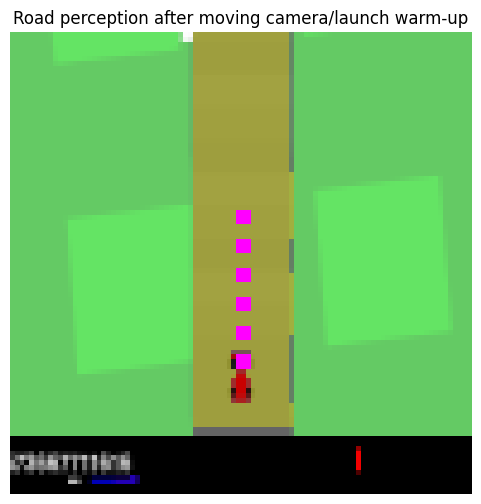

In [8]:
#@title 8. Perception + moving warm-up check
with gym.make(
    ENV_ID,
    render_mode="rgb_array",
    continuous=True,
    domain_randomize=False,
    max_episode_steps=MAX_STEPS,
) as env:
    obs, _, warmup_reward, warm_control, warm_vision = reset_and_warmup(env, SEED)

    print("camera/launch warm-up:", CAMERA_WARMUP_FRAMES, "frames /", CAMERA_WARMUP_FRAMES / SIM_FPS, "simulated s")
    print("warm-up reward:", round(warmup_reward, 3))
    print("warm-up final speed:", round(warm_vision["speed"], 3))
    print("warm-up final control:", [round(float(x), 3) for x in warm_control])
    print(json.dumps(warm_vision, indent=2))

    if warm_vision["speed"] < 1.0:
        raise RuntimeError(
            "Launch warm-up failed: car is still stationary. "
            "Do not start Laya control until this is fixed."
        )

    plt.figure(figsize=(6, 6))
    plt.imshow(perception_overlay(obs))
    plt.title("Road perception after moving camera/launch warm-up")
    plt.axis("off")
    plt.show()


In [9]:
#@title 9. Run local Laya racing v3
policy = LayaCarRacingPolicy(router)

env = gym.make(
    ENV_ID,
    render_mode="rgb_array",
    continuous=True,
    domain_randomize=False,
    max_episode_steps=MAX_STEPS,
)

warmup_frames_for_video = []
obs, _, episode_return, current_control, warm_vision = reset_and_warmup(
    env, SEED, record_frames=warmup_frames_for_video
)
step = CAMERA_WARMUP_FRAMES

reward_history, speed_history = [], []
steer_history, long_history = [], []
visibility_history, confidence_history, blend_history = [], [], []
decision_log, gif_frames = [], []

laya_failures = 0
last_progress_step = step
visited = int(env.unwrapped.tile_visited_count)
terminated = truncated = False
stop_reason = "frame_limit"

# Presentation-only movie HUD. Nothing here feeds back into policy/control.
from PIL import ImageDraw, ImageFont

def _hud_font(size, bold=False):
    candidates = [
        "/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf" if bold
        else "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf",
        "/usr/share/fonts/truetype/liberation2/LiberationSans-Bold.ttf" if bold
        else "/usr/share/fonts/truetype/liberation2/LiberationSans-Regular.ttf",
    ]
    for candidate in candidates:
        try:
            return ImageFont.truetype(candidate, size=size)
        except Exception:
            pass
    return ImageFont.load_default()

_HUD_TITLE = _hud_font(22, bold=True)
_HUD_HEAD = _hud_font(15, bold=True)
_HUD_TEXT = _hud_font(14)
_HUD_SMALL = _hud_font(12)

def _fmt_ms(value):
    return "--" if value is None else f"{float(value):.1f} ms"

def make_movie_frame(
    frame,
    *,
    phase,
    step=None,
    vision=None,
    decision=None,
    control=None,
    episode_return=None,
    visited=None,
    total_tiles=None,
):
    """Presentation frame only; returned pixels are never used by the controller."""
    arr = np.asarray(frame, dtype=np.uint8)
    resampling = getattr(PILImage, "Resampling", PILImage)
    game = PILImage.fromarray(arr).resize((432, 432), resampling.BICUBIC)

    canvas = PILImage.new("RGB", (768, 432), (14, 18, 25))
    canvas.paste(game, (0, 0))
    draw = ImageDraw.Draw(canvas)

    try:
        perception = PILImage.fromarray(perception_overlay(arr)).resize(
            (144, 144), resampling.NEAREST
        )
    except Exception:
        perception = PILImage.fromarray(arr).resize((144, 144), resampling.BICUBIC)

    px, py = 570, 62
    canvas.paste(perception, (px, py))
    draw.rectangle(
        (px - 1, py - 1, px + 144, py + 144),
        outline=(115, 132, 156),
        width=1,
    )

    draw.text((452, 14), "Laya x CarRacing", font=_HUD_TITLE, fill=(240, 244, 250))
    draw.text((452, 40), phase, font=_HUD_SMALL, fill=(163, 177, 198))
    draw.text((452, 62), "PERCEPTION", font=_HUD_SMALL, fill=(163, 177, 198))

    y = 220
    line = 23
    if step is not None:
        draw.text((452, y), f"Frame        {int(step):4d}", font=_HUD_TEXT, fill=(233, 238, 246))
        y += line

    if vision is not None:
        draw.text((452, y), f"Speed        {float(vision.get('speed', 0.0)):5.1f}", font=_HUD_TEXT, fill=(233, 238, 246))
        y += line
        draw.text((452, y), f"Road         {str(vision.get('road_direction', 'unknown'))}", font=_HUD_TEXT, fill=(233, 238, 246))
        y += line

    if decision is not None:
        latency = decision.get("latency_ms")
        steering = decision["steering_answer"]["choice"]
        longitudinal = decision["longitudinal_answer"]["choice"]
        confidence = float(decision.get("confidence", 0.0))
        draw.text((452, y), f"Intent       {steering}/{longitudinal}", font=_HUD_TEXT, fill=(233, 238, 246))
        y += line
        draw.text((452, y), f"Confidence   {confidence:5.3f}", font=_HUD_TEXT, fill=(233, 238, 246))
        y += line
        draw.text((452, y), f"Response     {_fmt_ms(latency)}", font=_HUD_HEAD, fill=(255, 218, 121))
        y += line

    if control is not None:
        draw.text(
            (452, y),
            f"Control      steer {float(control[0]):+.2f}  long {float(control[1]):+.2f}",
            font=_HUD_SMALL,
            fill=(205, 214, 228),
        )
        y += line

    if episode_return is not None:
        draw.text((452, y), f"Return       {float(episode_return):+7.1f}", font=_HUD_TEXT, fill=(233, 238, 246))
        y += line

    if visited is not None and total_tiles:
        coverage = 100.0 * float(visited) / max(float(total_tiles), 1.0)
        draw.text(
            (452, y),
            f"Track        {int(visited)}/{int(total_tiles)}  ({coverage:4.1f}%)",
            font=_HUD_TEXT,
            fill=(233, 238, 246),
        )

    draw.line((432, 0, 432, 432), fill=(58, 69, 86), width=2)
    return np.asarray(canvas)

writer = imageio.get_writer(
    VIDEO_PATH,
    format="FFMPEG",
    mode="I",
    fps=SIM_FPS / VIDEO_EVERY,
    codec="libx264",
    pixelformat="yuv420p",
    macro_block_size=1,
)

# Include the warm-up in the video at the same sampling rate.
for i, frame in enumerate(warmup_frames_for_video):
    if i % VIDEO_EVERY == 0:
        writer.append_data(
            make_movie_frame(
                frame,
                phase="camera + launch warm-up",
                step=i + 1,
            )
        )

try:
    while step < MAX_STEPS:
        vision_before = extract_visual_state(
            obs, read_speed(env), read_angular_velocity(env)
        )
        no_progress_frames = step - last_progress_step

        try:
            decision = policy.decide(
                vision_before,
                episode_return,
                step,
                current_control,
            )
        except Exception as error:
            laya_failures += 1
            # Do not kill the whole system for a single model call.
            ref = reference_control(vision_before, force_launch=(vision_before["speed"] < ANTI_STALL_SPEED))
            decision = {
                "steering_answer": {"choice": expected_steering_from_vision(vision_before), "confidence": 0.0, "probabilities": {}, "choice_probability": 0.0, "probability_margin": 0.0},
                "longitudinal_answer": {"choice": "accelerate" if vision_before["speed"] < 20 else "hold", "confidence": 0.0, "probabilities": {}, "choice_probability": 0.0, "probability_margin": 0.0},
                "confidence": 0.0,
                "latency_ms": None,
                "raw_target": ref.copy(),
                "state": {},
                "error": repr(error),
            }

        target, resolution = resolve_control(
            decision,
            vision_before,
            no_progress_frames,
            PREFLIGHT_PASSED,
        )

        rewards = []
        tiles_before = int(env.unwrapped.tile_visited_count)

        for _ in range(min(CONTROL_HORIZON, MAX_STEPS - step)):
            current_control = slew(current_control, target)
            action = to_gym_action(current_control)

            if not np.isfinite(action).all() or action.shape != (3,):
                raise RuntimeError(f"Invalid motor action: {action}")
            if not env.action_space.contains(action):
                raise RuntimeError(f"Motor action outside CarRacing action space: {action}")

            obs, reward, terminated, truncated, _ = env.step(action)
            episode_return += float(reward)
            rewards.append(float(reward))
            step += 1

            vision_after = extract_visual_state(
                obs, read_speed(env), read_angular_velocity(env)
            )

            reward_history.append(float(episode_return))
            speed_history.append(float(vision_after["speed"]))
            steer_history.append(float(current_control[0]))
            long_history.append(float(current_control[1]))
            visibility_history.append(float(vision_after["road_visibility"]))

            current_visited = int(env.unwrapped.tile_visited_count)
            if current_visited > visited:
                visited = current_visited
                last_progress_step = step

            render_frame = None
            if step % VIDEO_EVERY == 0 or step % GIF_EVERY == 0:
                render_frame = env.render()

            movie_frame = None
            if render_frame is not None:
                movie_frame = make_movie_frame(
                    render_frame,
                    phase="Laya-1.2-speedup control",
                    step=step,
                    vision=vision_after,
                    decision=decision,
                    control=current_control,
                    episode_return=episode_return,
                    visited=visited,
                    total_tiles=len(env.unwrapped.track),
                )

            if step % VIDEO_EVERY == 0:
                writer.append_data(movie_frame)

            if step % GIF_EVERY == 0:
                resampling = getattr(PILImage, "Resampling", PILImage)
                gif_frames.append(
                    np.asarray(
                        PILImage.fromarray(movie_frame).resize(
                            (640, 360), resampling.LANCZOS
                        )
                    )
                )

            if terminated or truncated:
                stop_reason = "terminated" if terminated else "time_limit"
                break

            if (step - last_progress_step) >= STOP_AFTER_FRAMES:
                stop_reason = "no_new_tiles_after_recovery"
                break

        tiles_after = int(env.unwrapped.tile_visited_count)
        tiles_gained = tiles_after - tiles_before
        horizon_reward = float(np.sum(rewards))
        vision_after = extract_visual_state(
            obs, read_speed(env), read_angular_velocity(env)
        )

        policy.record(decision, horizon_reward, tiles_gained, vision_after)

        entry = {
            "step": int(step),
            "confidence": float(decision["confidence"]),
            "latency_ms": None if decision["latency_ms"] is None else float(decision["latency_ms"]),
            "steering_answer": decision["steering_answer"],
            "longitudinal_answer": decision["longitudinal_answer"],
            "raw_laya_control": resolution["raw_laya_control"],
            "semantic_laya_control": resolution.get("semantic_laya_control"),
            "raw_steering_answer": decision.get("raw_steering_answer"),
            "raw_longitudinal_answer": decision.get("raw_longitudinal_answer"),
            "semantic_overrides": decision.get("semantic_overrides", []),
            "model_confidence": float(decision.get("model_confidence", decision["confidence"])),
            "reference_control": resolution["reference_control"],
            "resolved_target": [float(x) for x in target],
            "applied_control": [float(x) for x in current_control],
            "laya_blend": float(resolution["laya_blend"]),
            "resolution_reasons": resolution["reasons"],
            "expected_steering": resolution["expected_steering"],
            "steering_consistent": resolution["steering_consistent"],
            "pedal_consistent": resolution["pedal_consistent"],
            "reward_horizon": horizon_reward,
            "return_total": float(episode_return),
            "tiles": int(visited),
            "tiles_gained": int(tiles_gained),
            "no_progress_frames": int(step - last_progress_step),
            "vision_before": vision_before,
            "vision_after": vision_after,
        }
        if "error" in decision:
            entry["laya_error"] = decision["error"]

        decision_log.append(entry)
        confidence_history.append(float(decision["confidence"]))
        blend_history.append(float(resolution["laya_blend"]))

        if len(decision_log) <= 15 or len(decision_log) % 20 == 0:
            lat = "ERR" if decision["latency_ms"] is None else f"{decision['latency_ms']:.1f}ms"
            print(
                f"decision {len(decision_log):04d} | step {step:04d} | "
                f"Laya {decision['steering_answer']['choice']}/{decision['longitudinal_answer']['choice']} | "
                f"conf {decision['confidence']:.3f} | blend {resolution['laya_blend']:.2f} | {lat} | "
                f"return {episode_return:+.1f} | steer {current_control[0]:+.2f} | long {current_control[1]:+.2f} | "
                f"road {vision_after['road_direction']} | speed {vision_after['speed']:.1f} | "
                f"tiles {visited}/{len(env.unwrapped.track)} | "
                f"override {','.join(resolution['reasons'])}"
            )

        if terminated or truncated or stop_reason == "no_new_tiles_after_recovery":
            break

    coverage = float(visited) / float(len(env.unwrapped.track)) if len(env.unwrapped.track) else 0.0

finally:
    writer.close()
    env.close()

if gif_frames:
    imageio.mimsave(
        GIF_PATH,
        gif_frames,
        duration=1000.0 * GIF_EVERY / SIM_FPS,
        loop=0,
    )

latencies = [d["latency_ms"] for d in decision_log if d.get("latency_ms") is not None]
confidences = [d["confidence"] for d in decision_log]
blends = [d["laya_blend"] for d in decision_log]

summary = {
    "model": MODEL_ID,
    "model_revision": repo_info.sha,
    "head_budget": int(model_cfg["head_context_budget"]),
    "model_interface": "typed-decision option scores; uncalibrated probabilities",
    "device": DEVICE,
    "control_mode": CONTROL_MODE,
    "seed": SEED,
    "camera_warmup_frames": CAMERA_WARMUP_FRAMES,
    "camera_settle_frames": CAMERA_SETTLE_FRAMES,
    "warmup_final_speed": float(warm_vision["speed"]),
    "model_warmup_calls": MODEL_WARMUP_CALLS,
    "model_warmup_total_wall_ms": float(model_warmup_wall_ms),
    "steps_total_including_warmup": int(step),
    "controlled_steps": int(max(0, step - CAMERA_WARMUP_FRAMES)),
    "total_reward_including_warmup": float(episode_return),
    "road_coverage": float(coverage),
    "tiles_visited": int(visited),
    "decisions": int(len(decision_log)),
    "preflight_passed": bool(PREFLIGHT_PASSED),
    "stop_reason": stop_reason,
    "laya_failures": int(laya_failures),
    "mean_laya_latency_ms": float(np.mean(latencies)) if latencies else None,
    "p95_laya_latency_ms": float(np.percentile(latencies, 95)) if latencies else None,
    "mean_laya_confidence": float(np.mean(confidences)) if confidences else None,
    "mean_laya_blend": float(np.mean(blends)) if blends else None,
    "max_laya_blend": float(np.max(blends)) if blends else None,
    "actual_model_influence_decisions": int(sum(x > 0 for x in blends)),
    "model_influence_fraction": float(np.mean(np.asarray(blends)>0)) if blends else None,
    "mean_raw_model_confidence": float(np.mean([d.get("model_confidence",0) for d in decision_log])) if decision_log else None,
    "preflight_raw_agreement_fraction": float(np.mean([r["raw_model"]==r["expected"] for r in PREFLIGHT_RESULTS])) if PREFLIGHT_RESULTS else None,
    "steering_counts": dict(Counter(
        d["steering_answer"]["choice"] for d in decision_log
    )),
    "longitudinal_counts": dict(Counter(
        d["longitudinal_answer"]["choice"] for d in decision_log
    )),
    "override_counts": dict(Counter(
        reason for d in decision_log for reason in d["resolution_reasons"]
    )),
}

Path(LOG_PATH).write_text(
    json.dumps(
        {
            "summary": summary,
            "model_warmup_latencies_ms": warm_latencies,
            "preflight": PREFLIGHT_RESULTS,
            "decisions": decision_log,
        },
        indent=2,
        allow_nan=False,
    ),
    encoding="utf-8",
)

flat_rows = []
for d in decision_log:
    flat_rows.append({
        "step": d["step"],
        "steering": d["steering_answer"]["choice"],
        "longitudinal": d["longitudinal_answer"]["choice"],
        "confidence": d["confidence"],
        "laya_blend": d["laya_blend"],
        "latency_ms": d["latency_ms"],
        "resolved_steer": d["resolved_target"][0],
        "resolved_longitudinal": d["resolved_target"][1],
        "applied_steer": d["applied_control"][0],
        "applied_longitudinal": d["applied_control"][1],
        "reward_horizon": d["reward_horizon"],
        "return_total": d["return_total"],
        "tiles": d["tiles"],
        "tiles_gained": d["tiles_gained"],
        "road_direction": d["vision_before"]["road_direction"],
        "bearing": d["vision_before"]["visible_road_bearing_degrees"],
        "heading": d["vision_before"]["visible_road_heading_degrees"],
        "visibility": d["vision_before"]["road_visibility"],
        "speed": d["vision_before"]["speed"],
        "override": ",".join(d["resolution_reasons"]),
    })

pd.DataFrame(flat_rows).to_csv(CSV_PATH, index=False)

print("\n=== RESULT ===")
print(json.dumps(summary, indent=2))


decision 0001 | step 0054 | Laya straight/hold | conf 0.453 | blend 0.00 | 131.0ms | return +16.5 | steer +0.01 | long +0.12 | road straight | speed 32.0 | tiles 7/319 | override none
decision 0002 | step 0058 | Laya straight/hold | conf 0.532 | blend 0.00 | 97.4ms | return +19.3 | steer -0.03 | long -0.20 | road straight | speed 27.9 | tiles 8/319 | override none
decision 0003 | step 0062 | Laya straight/hold | conf 0.416 | blend 0.00 | 94.5ms | return +22.0 | steer +0.00 | long +0.12 | road straight | speed 28.5 | tiles 9/319 | override none
decision 0004 | step 0066 | Laya straight/hold | conf 0.448 | blend 0.00 | 142.5ms | return +21.6 | steer +0.01 | long +0.12 | road straight | speed 29.3 | tiles 9/319 | override none
decision 0005 | step 0070 | Laya straight/brake | conf 0.481 | blend 0.00 | 153.8ms | return +24.3 | steer +0.00 | long +0.12 | road straight | speed 30.1 | tiles 10/319 | override none
decision 0006 | step 0074 | Laya straight/brake | conf 0.587 | blend 0.00 | 196.

MP4:


GIF:


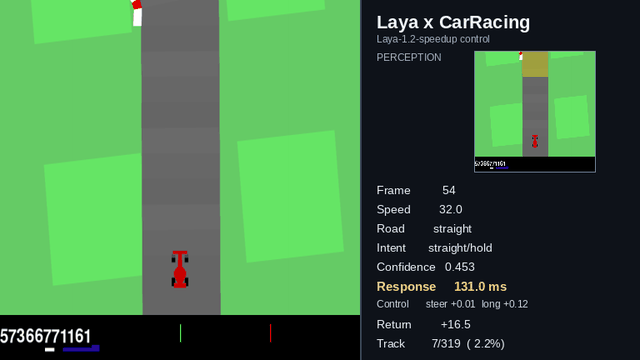


=== LOCAL RESPONSE TIME ===


,metric,latency_ms
0,first model call,1603.5
1,post-warm-up mean,59.2
2,run mean,85.4
3,run median (p50),83.3
4,run p95,93.3
5,run max,310.1


steady-state local Laya rate: 11.7 decisions/s


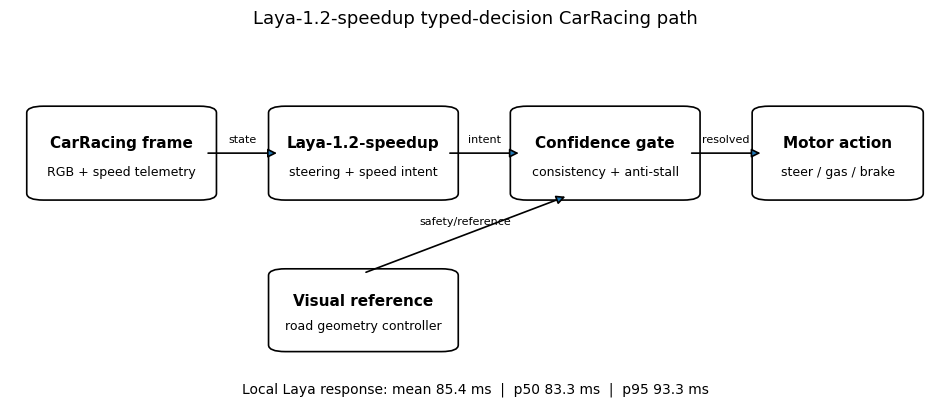

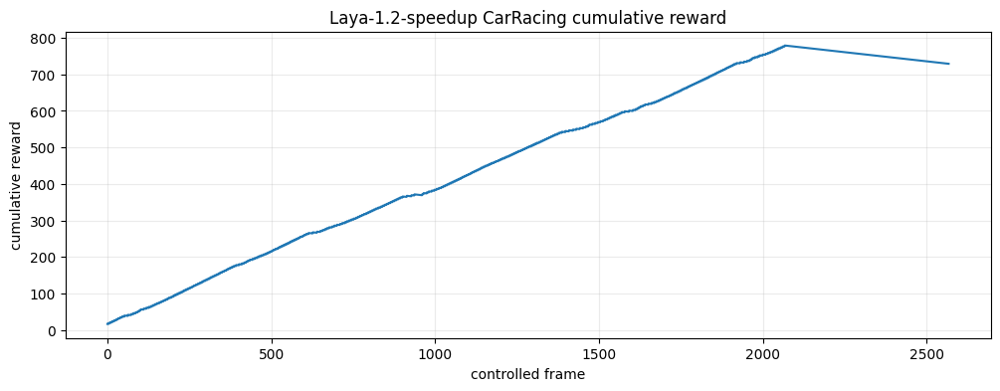

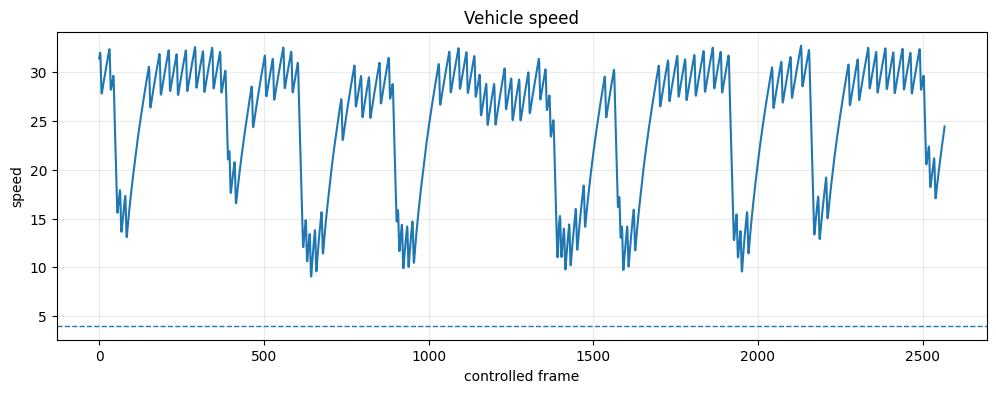

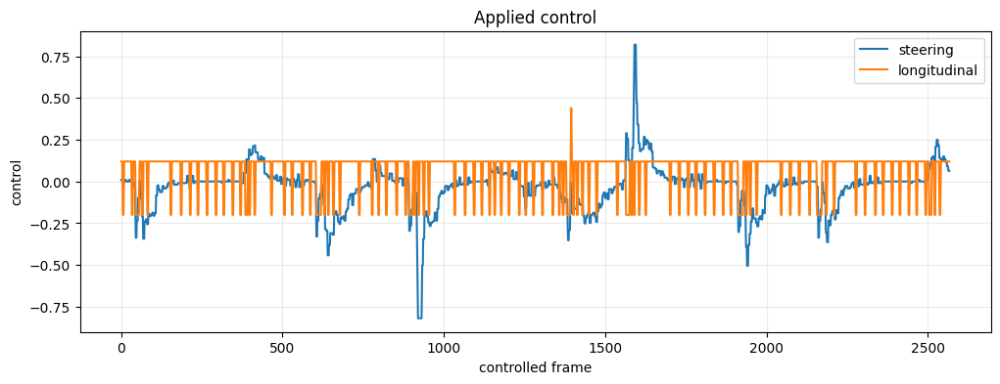

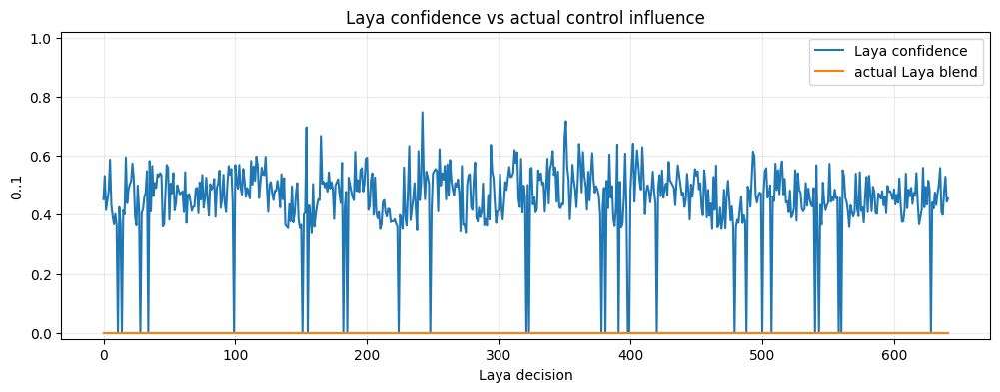

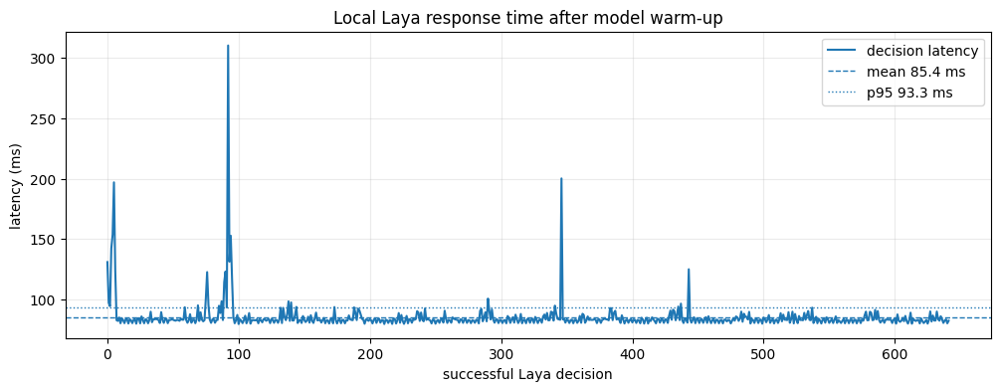

,step,steering,longitudinal,confidence,laya_blend,latency_ms,resolved_steer,resolved_longitudinal,applied_steer,applied_longitudinal,reward_horizon,return_total,tiles,tiles_gained,road_direction,bearing,heading,visibility,speed,override
612,2502,straight,hold,0.462512,0.0,89.130755,-0.009548,0.12,-0.009548,0.12,-0.4,740.395611,316,0,straight,0.000000,-0.954841,1.0,28.877166,tile_progress_recovery
613,2506,straight,hold,0.491535,0.0,80.006317,0.000000,0.12,0.000000,0.12,-0.4,739.995611,316,0,straight,0.000000,0.000000,1.0,29.687118,tile_progress_recovery
614,2510,straight,hold,0.436606,0.0,84.175721,0.000000,0.12,0.000000,0.12,-0.4,739.595611,316,0,straight,0.000000,0.000000,1.0,30.476376,tile_progress_recovery
615,2514,straight,hold,0.474279,0.0,82.943608,0.000000,0.12,0.000000,0.12,-0.4,739.195611,316,0,straight,0.000000,0.000000,1.0,31.247212,tile_progress_recovery
616,2518,straight,hold,0.468717,0.0,82.254447,0.000000,-0.20,0.000000,-0.20,-0.4,738.795611,316,0,straight,0.000000,0.000000,1.0,32.001311,tile_progress_recovery
617,2522,straight,hold,0.541662,0.0,83.028744,0.000000,0.12,0.000000,0.12,-0.4,738.395611,316,0,straight,0.000000,0.000000,1.0,27.879203,tile_progress_recovery
618,2526,straight,hold,0.438540,0.0,83.095272,0.009548,0.12,0.009548,0.12,-0.4,737.995611,316,0,straight,0.000000,0.954841,1.0,28.472604,tile_progress_recovery
619,2530,straight,hold,0.367589,0.0,80.262258,0.000000,0.12,0.000000,0.12,-0.4,737.595611,316,0,straight,0.000000,0.000000,1.0,29.292552,tile_progress_recovery
620,2534,straight,hold,0.391228,0.0,84.428144,0.000000,0.12,0.000000,0.12,-0.4,737.195611,316,0,straight,0.000000,0.000000,1.0,30.091016,tile_progress_recovery
621,2538,straight,hold,0.417128,0.0,82.220982,0.000000,0.12,0.000000,0.12,-0.4,736.795611,316,0,straight,0.000000,0.000000,1.0,30.870437,tile_progress_recovery


video: /content/laya_1p2_speedup_car_racing.mp4
gif: /content/laya_car_racing_local_v3.gif
preflight: /content/laya_car_racing_local_v3_preflight.json
log: /content/laya_car_racing_local_v3.json
csv: /content/laya_car_racing_local_v3_decisions.csv


In [10]:
#@title 10. Video and diagnostics
print("MP4:")
display(Video(VIDEO_PATH, embed=True, width=960, html_attributes="controls loop"))

if Path(GIF_PATH).exists():
    print("GIF:")
    display(Image(filename=GIF_PATH))

print("\n=== LOCAL RESPONSE TIME ===")
response_rows = []
if warm_latencies:
    response_rows.append({"metric": "first model call", "latency_ms": float(warm_latencies[0])})
if len(warm_latencies) > 1:
    response_rows.append({"metric": "post-warm-up mean", "latency_ms": float(np.mean(warm_latencies[1:]))})
if latencies:
    response_rows.extend([
        {"metric": "run mean", "latency_ms": float(np.mean(latencies))},
        {"metric": "run median (p50)", "latency_ms": float(np.percentile(latencies, 50))},
        {"metric": "run p95", "latency_ms": float(np.percentile(latencies, 95))},
        {"metric": "run max", "latency_ms": float(np.max(latencies))},
    ])

response_df = pd.DataFrame(response_rows)
if not response_df.empty:
    display(response_df.style.format({"latency_ms": "{:.1f}"}))
    if latencies and float(np.mean(latencies)) > 0:
        print(f"steady-state local Laya rate: {1000.0 / float(np.mean(latencies)):.1f} decisions/s")

# Architecture / data-flow diagram. Presentation only.
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(12, 4.8))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")

def _box(x, y, w, h, title, subtitle):
    patch = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.012,rounding_size=0.018",
        linewidth=1.2,
        fill=False,
    )
    ax.add_patch(patch)
    ax.text(x + w/2, y + h*0.62, title, ha="center", va="center", fontsize=11, fontweight="bold")
    ax.text(x + w/2, y + h*0.28, subtitle, ha="center", va="center", fontsize=9)

def _arrow(x1, y1, x2, y2, label=None):
    ax.add_patch(FancyArrowPatch(
        (x1, y1), (x2, y2),
        arrowstyle="-|>",
        mutation_scale=13,
        linewidth=1.2,
    ))
    if label:
        ax.text((x1+x2)/2, (y1+y2)/2 + 0.035, label, ha="center", va="center", fontsize=8)

_box(0.03, 0.58, 0.18, 0.23, "CarRacing frame", "RGB + speed telemetry")
_box(0.29, 0.58, 0.18, 0.23, "Laya-1.2-speedup", "steering + speed intent")
_box(0.55, 0.58, 0.18, 0.23, "Confidence gate", "consistency + anti-stall")
_box(0.81, 0.58, 0.16, 0.23, "Motor action", "steer / gas / brake")
_box(0.29, 0.17, 0.18, 0.20, "Visual reference", "road geometry controller")

_arrow(0.21, 0.695, 0.29, 0.695, "state")
_arrow(0.47, 0.695, 0.55, 0.695, "intent")
_arrow(0.73, 0.695, 0.81, 0.695, "resolved")
_arrow(0.38, 0.37, 0.60, 0.58, "safety/reference")

latency_note = "response time unavailable"
if latencies:
    latency_note = (
        f"Local Laya response: mean {np.mean(latencies):.1f} ms  |  "
        f"p50 {np.percentile(latencies, 50):.1f} ms  |  "
        f"p95 {np.percentile(latencies, 95):.1f} ms"
    )
ax.text(0.5, 0.055, latency_note, ha="center", va="center", fontsize=10)
ax.set_title("Laya-1.2-speedup typed-decision CarRacing path", fontsize=13, pad=12)
plt.show()


plt.figure(figsize=(12, 4))
plt.plot(reward_history)
plt.xlabel("controlled frame"); plt.ylabel("cumulative reward")
plt.title("Laya-1.2-speedup CarRacing cumulative reward")
plt.grid(True, alpha=0.25); plt.show()

plt.figure(figsize=(12, 4))
plt.plot(speed_history)
plt.axhline(ANTI_STALL_SPEED, linestyle="--", linewidth=1)
plt.xlabel("controlled frame"); plt.ylabel("speed")
plt.title("Vehicle speed")
plt.grid(True, alpha=0.25); plt.show()

plt.figure(figsize=(12, 4))
plt.plot(steer_history, label="steering")
plt.plot(long_history, label="longitudinal")
plt.xlabel("controlled frame"); plt.ylabel("control")
plt.title("Applied control")
plt.legend(); plt.grid(True, alpha=0.25); plt.show()

if confidence_history:
    plt.figure(figsize=(12, 4))
    plt.plot(confidence_history, label="Laya confidence")
    plt.plot(blend_history, label="actual Laya blend")
    plt.xlabel("Laya decision"); plt.ylabel("0..1")
    plt.ylim(-0.02, 1.02)
    plt.title("Laya confidence vs actual control influence")
    plt.legend(); plt.grid(True, alpha=0.25); plt.show()

if latencies:
    run_mean_ms = float(np.mean(latencies))
    run_p95_ms = float(np.percentile(latencies, 95))
    plt.figure(figsize=(12, 4))
    plt.plot(latencies, label="decision latency")
    plt.axhline(run_mean_ms, linestyle="--", linewidth=1, label=f"mean {run_mean_ms:.1f} ms")
    plt.axhline(run_p95_ms, linestyle=":", linewidth=1, label=f"p95 {run_p95_ms:.1f} ms")
    plt.xlabel("successful Laya decision"); plt.ylabel("latency (ms)")
    plt.title("Local Laya response time after model warm-up")
    plt.legend()
    plt.grid(True, alpha=0.25); plt.show()

display(pd.DataFrame(flat_rows).tail(30))
print("video:", VIDEO_PATH)
print("gif:", GIF_PATH)
print("preflight:", PREFLIGHT_PATH)
print("log:", LOG_PATH)
print("csv:", CSV_PATH)
